#Import Data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

BASE = "/content/drive/MyDrive/hmda/"
CLEAN = BASE + "clean_pandas/"
OUT = BASE + "rq3_pandas/"

os.makedirs(OUT, exist_ok=True)

sys.path.insert(0, BASE)
import rules

# Load only the columns needed for RQ3
COLS = [
    "action_taken", "denied_flag",
    "loan_type", "loan_purpose",
    "lien_status", "occupancy_type",
    "construction_method",
    "derived_loan_product_type",
    "state_code", "lei"
]
import pyarrow as pa
import pyarrow.parquet as pq

table = pq.read_table(
    CLEAN + "S1_orig_denied",
    columns=COLS
)

# Decode dictionary columns before converting to Pandas
for i, field in enumerate(table.schema):
    if pa.types.is_dictionary(field.type):
        table = table.set_column(
            i,
            field.name,
            table.column(i).cast(field.type.value_type)
        )

S1 = table.to_pandas(strings_to_categorical=True)

del table

print("Shape:", S1.shape)
S1.info(memory_usage="deep")

Mounted at /content/drive
Shape: (8300547, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8300547 entries, 0 to 8300546
Data columns (total 10 columns):
 #   Column                     Dtype   
---  ------                     -----   
 0   action_taken               category
 1   denied_flag                int8    
 2   loan_type                  category
 3   loan_purpose               category
 4   lien_status                category
 5   occupancy_type             category
 6   construction_method        category
 7   derived_loan_product_type  category
 8   state_code                 category
 9   lei                        category
dtypes: category(9), int8(1)
memory usage: 87.5 MB


#Data Understanding

In [2]:
# RQ3 — Variable Overview

overview = pd.DataFrame({
    "dtype": S1.dtypes.astype(str),
    "unique": S1.nunique(),
    "missing": S1.isna().sum(),
    "missing_pct": (S1.isna().mean() * 100).round(4)
})

display(overview)

,dtype,unique,missing,missing_pct
action_taken,category,2,0,0.0000
denied_flag,int8,2,0,0.0000
loan_type,category,4,0,0.0000
loan_purpose,category,6,0,0.0000
lien_status,category,2,0,0.0000
occupancy_type,category,3,0,0.0000
construction_method,category,2,0,0.0000
derived_loan_product_type,category,8,0,0.0000
state_code,category,54,36577,0.4407
lei,category,4909,0,0.0000


In [3]:
# Distribution of loan characteristics

CAT_COLS = [
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "derived_loan_product_type"
]

for col in CAT_COLS:
    print(f"\n--- {col} ---")
    display(S1[col].value_counts(dropna=False))


--- loan_type ---


,count
loan_type,
1,6601706
2,1072243
3,584996
4,41602



--- loan_purpose ---


,count
loan_purpose,
1,4158055
32,1165962
4,1078317
2,972499
31,922327
5,3387



--- lien_status ---


,count
lien_status,
1,6017194
2,2283353


... (2 outputs left out)


--- construction_method ---


,count
construction_method,
1,7846538
2,454009



--- derived_loan_product_type ---


,count
derived_loan_product_type,
Conventional:First Lien,4323685
Conventional:Subordinate Lien,2278021
FHA:First Lien,1071125
VA:First Lien,584977
FSA/RHS:First Lien,37407
FSA/RHS:Subordinate Lien,4195
FHA:Subordinate Lien,1118
VA:Subordinate Lien,19


##RQ3.1 — Denial Rate by Loan Characteristics

In [4]:
# Loan characteristics mapping

LABELS = {
    "loan_type": {
        "1": "Conventional",
        "2": "FHA",
        "3": "VA",
        "4": "FSA/RHS"
    },
    "loan_purpose": {
        "1": "Home purchase",
        "2": "Home improvement",
        "31": "Refinancing",
        "32": "Cash-out refinancing",
        "4": "Other purpose",
        "5": "Not applicable"
    },
    "lien_status": {
        "1": "First lien",
        "2": "Subordinate lien"
    },
    "occupancy_type": {
        "1": "Principal residence",
        "2": "Second residence",
        "3": "Investment property"
    },
    "construction_method": {
        "1": "Site-built",
        "2": "Manufactured home"
    }
}

In [5]:
# Reusable denial rate function

BASELINE = S1["denied_flag"].mean() * 100

def denial_summary(df, col):
    result = (
        df.groupby(col, observed=True, dropna=False)
        .agg(
            applications=("denied_flag", "size"),
            denied=("denied_flag", "sum")
        )
        .reset_index()
    )

    result["originated"] = (
        result["applications"] - result["denied"]
    )

    result["denial_rate"] = (
        result["denied"] / result["applications"] * 100
    )

    result["volume_share"] = (
        result["applications"] / len(df) * 100
    )

    result["gap_vs_baseline_pp"] = (
        result["denial_rate"] - BASELINE
    )

    return result.sort_values(
        "denial_rate", ascending=False
    )

print(f"Baseline denial rate: {BASELINE:.2f}%")

Baseline denial rate: 25.34%


In [6]:
RQ3_RESULTS = {}

for col in [
    "lien_status",
    "occupancy_type",
    "construction_method",
    "derived_loan_product_type"
]:
    result = denial_summary(S1, col)

    if col in LABELS:
        result["label"] = result[col].map(LABELS[col])
    else:
        result["label"] = result[col]

    RQ3_RESULTS[col] = result

    print(f"\n--- {col} ---")
    display(result.round(2))

    result.to_csv(
        OUT + f"denial_by_{col}.csv",
        index=False
    )


--- lien_status ---


,lien_status,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
1,2,2283353,857003,1426350,37.53,27.51,12.19,Subordinate lien
0,1,6017194,1246459,4770735,20.71,72.49,-4.63,First lien



--- occupancy_type ---


,occupancy_type,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
0,1,7468387,1929249,5539138,25.83,89.97,0.49,Principal residence
1,2,163409,39601,123808,24.23,1.97,-1.11,Second residence
2,3,668751,134612,534139,20.13,8.06,-5.21,Investment property



--- construction_method ---


,construction_method,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
1,2,454009,272372,181637,59.99,5.47,34.65,Manufactured home
0,1,7846538,1831090,6015448,23.34,94.53,-2.00,Site-built



--- derived_loan_product_type ---


,derived_loan_product_type,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,label
7,VA:Subordinate Lien,19,13,6,68.42,0.00,43.08,VA:Subordinate Lien
5,FHA:Subordinate Lien,1118,580,538,51.88,0.01,26.54,FHA:Subordinate Lien
2,Conventional:Subordinate Lien,2278021,856082,1421939,37.58,27.44,12.24,Conventional:Subordinate Lien
1,FHA:First Lien,1071125,239866,831259,22.39,12.90,-2.95,FHA:First Lien
3,Conventional:First Lien,4323685,907475,3416210,20.99,52.09,-4.35,Conventional:First Lien
0,VA:First Lien,584977,94158,490819,16.10,7.05,-9.25,VA:First Lien
4,FSA/RHS:First Lien,37407,4960,32447,13.26,0.45,-12.08,FSA/RHS:First Lien
6,FSA/RHS:Subordinate Lien,4195,328,3867,7.82,0.05,-17.52,FSA/RHS:Subordinate Lien


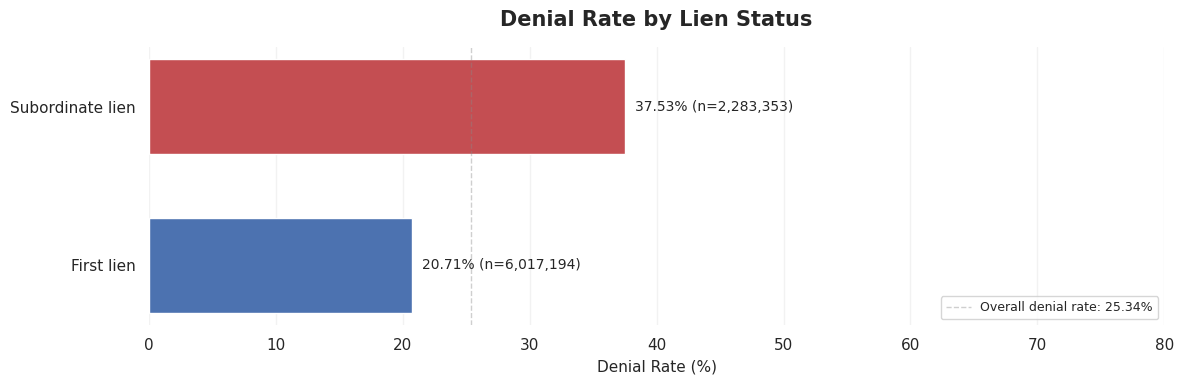

Updated: /content/drive/MyDrive/hmda/rq3_pandas/denial_by_lien_status.png
Groups displayed: 2/2
Groups excluded from chart: 0



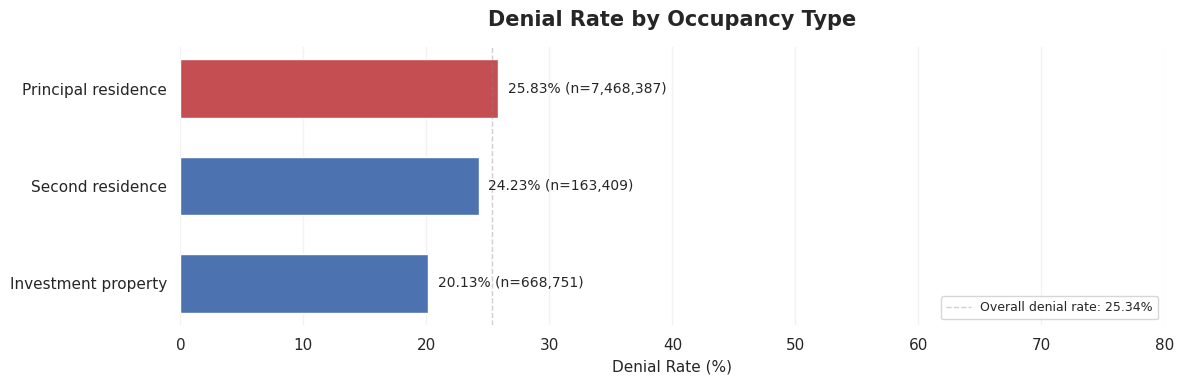

Updated: /content/drive/MyDrive/hmda/rq3_pandas/denial_by_occupancy_type.png
Groups displayed: 3/3
Groups excluded from chart: 0



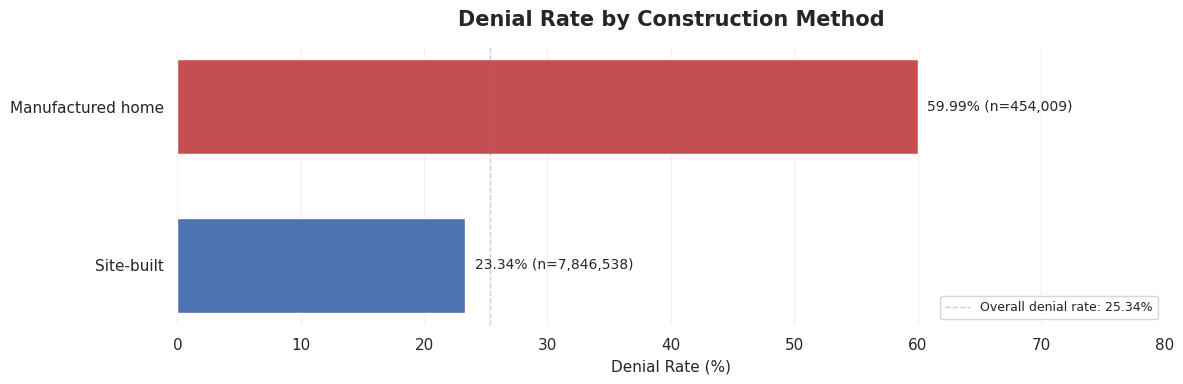

Updated: /content/drive/MyDrive/hmda/rq3_pandas/denial_by_construction_method.png
Groups displayed: 2/2
Groups excluded from chart: 0



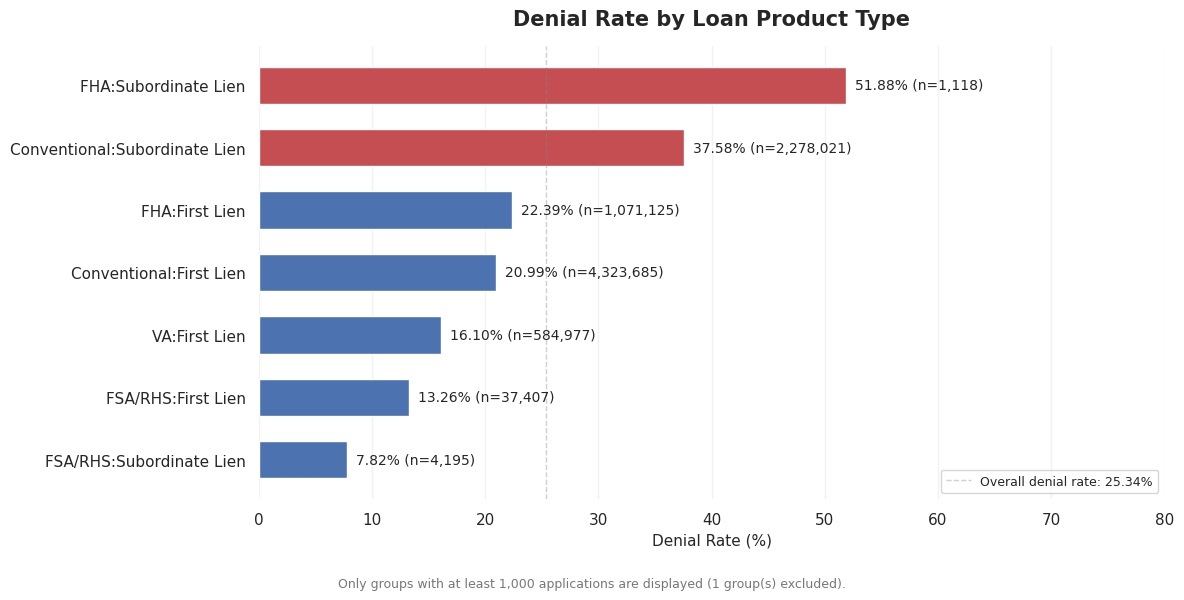

Updated: /content/drive/MyDrive/hmda/rq3_pandas/denial_by_derived_loan_product_type.png
Groups displayed: 7/8
Groups excluded from chart: 1



In [7]:
# RQ3.1 - Denial rates by loan characteristics
# Only visualize groups with at least 1,000 applications

import numpy as np

sns.set_theme(style="whitegrid")

MIN_SAMPLE = 1000
Z = 1.96

TITLES = {
    "lien_status": "Denial Rate by Lien Status",
    "occupancy_type": "Denial Rate by Occupancy Type",
    "construction_method": "Denial Rate by Construction Method",
    "derived_loan_product_type": "Denial Rate by Loan Product Type"
}


# Calculate Wilson confidence intervals
def wilson_ci(denied, n, z=1.96):

    p = denied / n
    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = (
        z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2))
        / denominator
    )

    lower = np.clip(center - margin, 0, 1)
    upper = np.clip(center + margin, 0, 1)

    return lower * 100, upper * 100


for col, title in TITLES.items():

    # Full statistical results
    df_full = RQ3_RESULTS[col].copy()

    df_full["ci_lower"], df_full["ci_upper"] = wilson_ci(
        df_full["denied"],
        df_full["applications"],
        Z
    )

    df_full["low_sample"] = (
        df_full["applications"] < MIN_SAMPLE
    )

    # Preserve all groups in result dictionary
    RQ3_RESULTS[col] = df_full.copy()

    # Overwrite existing CSV without filtering
    df_full.to_csv(
        os.path.join(OUT, f"denial_by_{col}.csv"),
        index=False
    )

    # Filter only for visualization
    df = df_full[
        df_full["applications"] >= MIN_SAMPLE
    ].copy()

    excluded = len(df_full) - len(df)

    df = df.sort_values(
        "denial_rate", ascending=True
    ).reset_index(drop=True)

    # Red: above baseline
    # Blue: below baseline
    colors = [
        "#C44E52" if rate > BASELINE else "#4C72B0"
        for rate in df["denial_rate"]
    ]

    fig, ax = plt.subplots(
        figsize=(12, max(4, len(df) * 0.65 + 1.5))
    )

    # Horizontal bar chart
    bars = ax.barh(
        df["label"].astype(str),
        df["denial_rate"],
        color=colors,
        height=0.6
    )

    # Overall denial rate
    ax.axvline(
        BASELINE,
        color="#888888",
        linestyle="--",
        linewidth=1,
        alpha=0.4,
        label=f"Overall denial rate: {BASELINE:.2f}%"
    )

    # Add denial rate and application volume
    for bar, rate, n in zip(
        bars,
        df["denial_rate"],
        df["applications"]
    ):

        ax.text(
            rate + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.2f}% (n={n:,})",
            va="center",
            fontsize=10
        )

    # Chart formatting
    ax.set_title(
        title,
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Denial Rate (%)", fontsize=11)
    ax.set_ylabel("")
    ax.set_xlim(0, 80)

    ax.legend(
        loc="lower right",
        frameon=True,
        fontsize=9
    )

    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

    sns.despine(left=True, bottom=True)

    # Sample size note
    if excluded > 0:

        fig.text(
            0.5,
            0.015,
            f"Only groups with at least {MIN_SAMPLE:,} "
            f"applications are displayed "
            f"({excluded} group(s) excluded).",
            ha="center",
            fontsize=9,
            color="#777777"
        )

        plt.tight_layout(rect=[0, 0.05, 1, 1])

    else:

        plt.tight_layout()

    # Overwrite existing chart
    filepath = os.path.join(
        OUT, f"denial_by_{col}.png"
    )

    fig.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()
    plt.close(fig)

    print(f"Updated: {filepath}")
    print(f"Groups displayed: {len(df)}/{len(df_full)}")
    print(f"Groups excluded from chart: {excluded}\n")

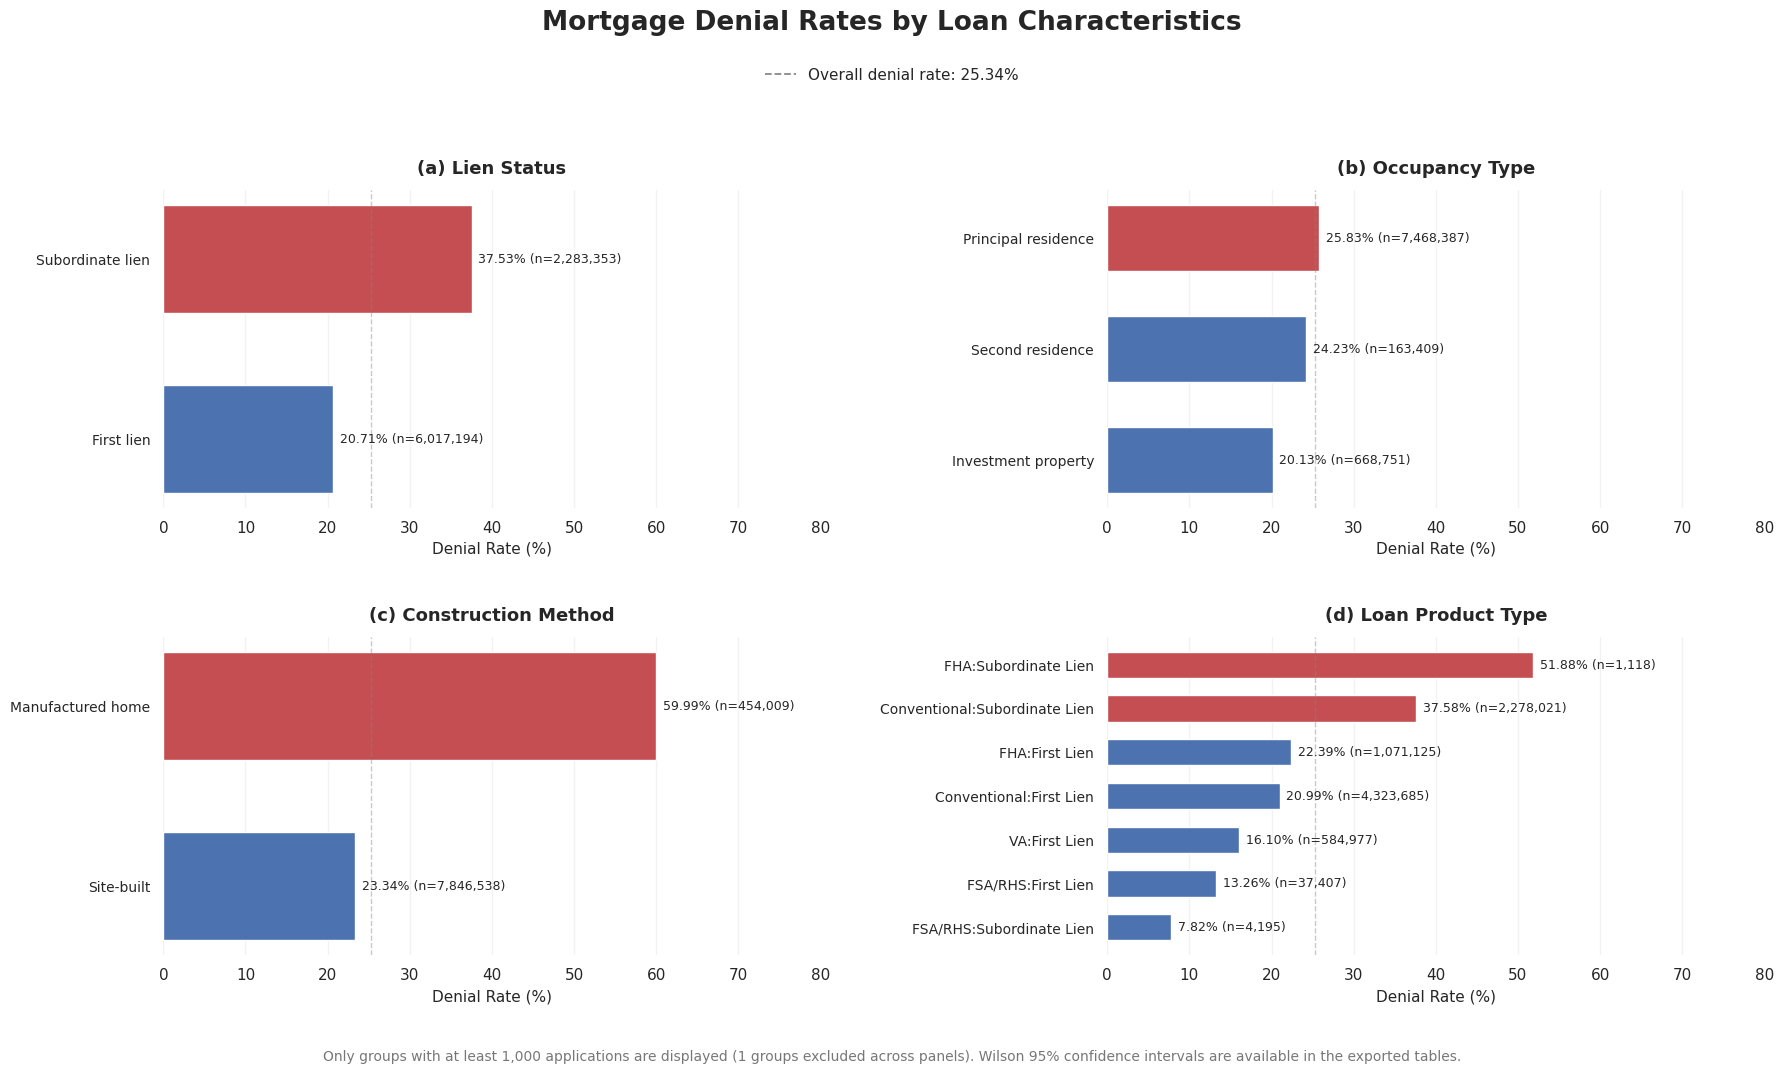

Saved: /content/drive/MyDrive/hmda/rq3_pandas/denial_by_loan_characteristics_combined.png


In [27]:
# ============================================================
# RQ3.1 - DENIAL RATES BY LOAN CHARACTERISTICS
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

sns.set_theme(style="whitegrid")

MIN_SAMPLE = 1000
Z = 1.96

TITLES = {
    "lien_status": "(a) Lien Status",
    "occupancy_type": "(b) Occupancy Type",
    "construction_method": "(c) Construction Method",
    "derived_loan_product_type": "(d) Loan Product Type"
}


# ------------------------------------------------------------
# Step 1: Calculate Wilson confidence intervals
# ------------------------------------------------------------

def wilson_ci(denied, n, z=1.96):

    p = denied / n
    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = (
        z * np.sqrt(
            p * (1 - p) / n + z**2 / (4 * n**2)
        ) / denominator
    )

    lower = np.clip(center - margin, 0, 1)
    upper = np.clip(center + margin, 0, 1)

    return lower * 100, upper * 100


# ------------------------------------------------------------
# Step 2: Initialize combined figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 11),
    sharex=True
)

axes = axes.flatten()

excluded_total = 0


# ------------------------------------------------------------
# Step 3: Generate four subplots
# ------------------------------------------------------------

for ax, (col, title) in zip(axes, TITLES.items()):

    df_full = RQ3_RESULTS[col].copy()

    df_full["ci_lower"], df_full["ci_upper"] = wilson_ci(
        df_full["denied"],
        df_full["applications"],
        Z
    )

    df_full["low_sample"] = (
        df_full["applications"] < MIN_SAMPLE
    )

    # Preserve full statistical results
    RQ3_RESULTS[col] = df_full.copy()

    df_full.to_csv(
        os.path.join(OUT, f"denial_by_{col}.csv"),
        index=False
    )

    # Filter only for visualization
    df = df_full[
        df_full["applications"] >= MIN_SAMPLE
    ].copy()

    excluded_total += len(df_full) - len(df)

    df = df.sort_values(
        "denial_rate",
        ascending=True
    ).reset_index(drop=True)

    colors = [
        "#C44E52" if rate > BASELINE else "#4C72B0"
        for rate in df["denial_rate"]
    ]

    bars = ax.barh(
        df["label"].astype(str),
        df["denial_rate"],
        color=colors,
        height=0.6
    )

    # Overall denial rate
    ax.axvline(
        BASELINE,
        color="#888888",
        linestyle="--",
        linewidth=1.0,
        alpha=0.45
    )

    # Add denial rate and application volume
    for bar, rate, n in zip(
        bars,
        df["denial_rate"],
        df["applications"]
    ):

        ax.text(
            rate + 0.8,
            bar.get_y() + bar.get_height() / 2,
            f"{rate:.2f}% (n={n:,})",
            va="center",
            fontsize=9
        )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Denial Rate (%)", fontsize=11)
    ax.set_ylabel("")
    ax.set_xlim(0, 80)

    ax.tick_params(axis="y", labelsize=10)
    ax.tick_params(axis="x", labelbottom=True)

    ax.grid(axis="x", alpha=0.25)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax, left=True, bottom=True)


# ------------------------------------------------------------
# Step 4: Add shared title, legend and note
# ------------------------------------------------------------

fig.suptitle(
    "Mortgage Denial Rates by Loan Characteristics",
    fontsize=19,
    fontweight="bold",
    y=0.98
)

legend_elements = [
    Line2D(
        [0], [0],
        color="#888888",
        linestyle="--",
        linewidth=1.3,
        label=f"Overall denial rate: {BASELINE:.2f}%"
    )
]

fig.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    frameon=False,
    fontsize=11
)

fig.text(
    0.5,
    0.025,
    f"Only groups with at least {MIN_SAMPLE:,} applications "
    f"are displayed ({excluded_total} groups excluded across panels). "
    "Wilson 95% confidence intervals are available in the exported tables.",
    ha="center",
    fontsize=10,
    color="#777777"
)

plt.tight_layout(
    rect=[0, 0.06, 1, 0.90],
    h_pad=3,
    w_pad=3
)


# ------------------------------------------------------------
# Step 5: Export combined figure
# ------------------------------------------------------------

filepath = os.path.join(
    OUT,
    "denial_by_loan_characteristics_combined.png"
)

fig.savefig(
    filepath,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Saved: {filepath}")

### Insight 3.1 – Denial Rate by Loan Characteristics

Mortgage denial rates vary substantially across loan and property
characteristics, compared with the overall denial rate of 25.34%.

- **Lien status:** Subordinate-lien loans exhibit a denial rate of
  37.53%, compared with 20.71% for first-lien loans, representing
  a difference of 16.82 percentage points.

- **Occupancy type:** Principal residences have the highest denial
  rate (25.83%), followed by second residences (24.23%) and
  investment properties (20.13%). However, the differences are
  relatively modest compared with other loan characteristics.

- **Construction method:** Manufactured homes exhibit a denial
  rate of 59.99%, approximately 2.57 times that of site-built
  properties (23.34%). Although manufactured homes account for
  only 5.47% of applications, they represent a segment with
  particularly elevated denial rates.

- **Loan product type:** Conventional subordinate-lien loans
  have a denial rate of 37.58%, compared with 20.99% for
  conventional first-lien loans. However, this relationship is
  not consistent across all loan types, suggesting potential
  interaction effects between loan type and lien status.

Overall, construction method and lien status emerge as particularly
relevant characteristics for understanding mortgage denial patterns.
These variables should be considered as candidate predictors in RQ4,
subject to feature availability and leakage assessment.

Categories with fewer than 1,000 applications are excluded from
visualizations but retained in the statistical results.

##RQ3.2 – Geographic Analysis

In [9]:
# RQ3.2 - Denial rate by state

state_results = denial_summary(S1, "state_code")

# Store missing state records separately
state_missing = state_results[
    state_results["state_code"].isna()
].copy()

# Valid geographic records
state_results = state_results[
    state_results["state_code"].notna()
].copy()

state_results = state_results.sort_values(
    "denial_rate", ascending=False
).reset_index(drop=True)

# Save results
RQ3_RESULTS["state_code"] = state_results

state_results.to_csv(
    OUT + "denial_by_state.csv", index=False
)

state_missing.to_csv(
    OUT + "missing_state_summary.csv", index=False
)

print(f"Overall denial rate: {BASELINE:.2f}%")
print(f"Number of states/territories: {len(state_results)}")

display(state_results.round(2))

print("\nMissing state records:")
display(state_missing.round(2))

Overall denial rate: 25.34%
Number of states/territories: 54


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
0,MS,72904,23281,49623,31.93,0.88,6.59
1,LA,91609,29234,62375,31.91,1.10,6.57
2,HI,23327,7190,16137,30.82,0.28,5.48
3,FL,683860,207409,476451,30.33,8.24,4.99
4,WV,38419,11271,27148,29.34,0.46,4.00
5,GA,316285,88543,227742,27.99,3.81,2.65
6,AL,144489,39905,104584,27.62,1.74,2.28
7,TX,679129,184473,494656,27.16,8.18,1.82
8,NJ,215234,58375,156859,27.12,2.59,1.78
9,NM,50036,13434,36602,26.85,0.60,1.51



Missing state records:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
54,NaN,36577,31465,5112,86.02,0.44,60.68


In [10]:
# Geographic summary statistics

print("Denial rate distribution across states:")

display(
    state_results["denial_rate"]
    .describe()
    .round(2)
)

print("\nTop 10 highest denial rates:")

display(
    state_results.nlargest(10, "denial_rate")
    .round(2)
)

print("\nTop 10 lowest denial rates:")

display(
    state_results.nsmallest(10, "denial_rate")
    .round(2)
)

print("\nTop 10 states by application volume:")

display(
    state_results.nlargest(10, "applications")
    .round(2)
)

Denial rate distribution across states:


,denial_rate
count,54.00
mean,23.50
std,4.32
min,9.68
25%,21.10
50%,23.96
75%,26.21
max,31.93



Top 10 highest denial rates:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
0,MS,72904,23281,49623,31.93,0.88,6.59
1,LA,91609,29234,62375,31.91,1.10,6.57
2,HI,23327,7190,16137,30.82,0.28,5.48
3,FL,683860,207409,476451,30.33,8.24,4.99
4,WV,38419,11271,27148,29.34,0.46,4.00
5,GA,316285,88543,227742,27.99,3.81,2.65
6,AL,144489,39905,104584,27.62,1.74,2.28
7,TX,679129,184473,494656,27.16,8.18,1.82
8,NJ,215234,58375,156859,27.12,2.59,1.78
9,NM,50036,13434,36602,26.85,0.60,1.51



Top 10 lowest denial rates:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
53,GU,124,12,112,9.68,0.00,-15.66
52,ND,15351,2244,13107,14.62,0.18,-10.72
51,IA,81055,13306,67749,16.42,0.98,-8.93
50,SD,19267,3371,15896,17.50,0.23,-7.85
49,MN,136569,23926,112643,17.52,1.65,-7.82
48,NE,46622,8266,38356,17.73,0.56,-7.61
47,WI,167105,29743,137362,17.80,2.01,-7.54
46,VI,44,8,36,18.18,0.00,-7.16
45,KS,67639,13548,54091,20.03,0.81,-5.31
44,VT,14713,2963,11750,20.14,0.18,-5.20



Top 10 states by application volume:


,state_code,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp
15,CA,691809,180539,511270,26.10,8.33,0.76
3,FL,683860,207409,476451,30.33,8.24,4.99
7,TX,679129,184473,494656,27.16,8.18,1.82
21,NC,342338,85548,256790,24.99,4.12,-0.35
19,PA,328267,82238,246029,25.05,3.95,-0.29
25,OH,325801,79557,246244,24.42,3.93,-0.92
5,GA,316285,88543,227742,27.99,3.81,2.65
12,NY,283359,74541,208818,26.31,3.41,0.96
20,MI,274802,68679,206123,24.99,3.31,-0.35
26,IL,273687,66078,207609,24.14,3.30,-1.20


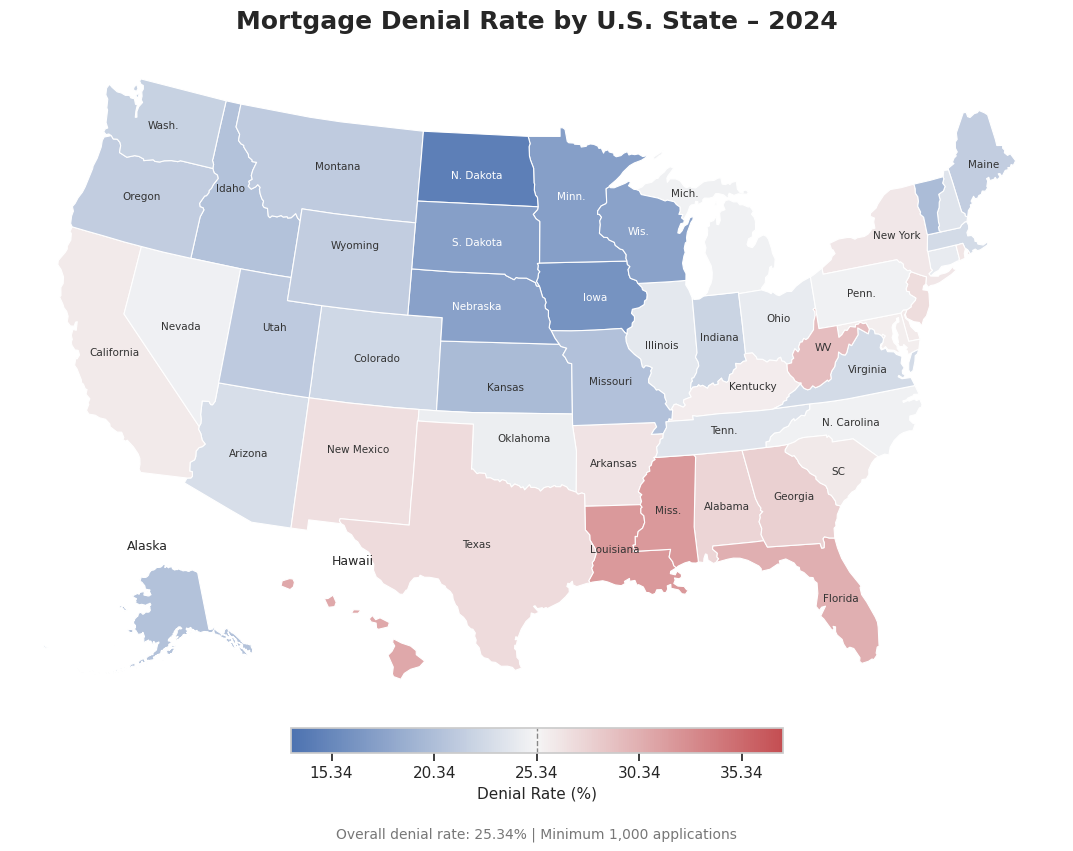

Saved: /content/drive/MyDrive/hmda/rq3_pandas/denial_rate_us_map.png


In [11]:
# RQ3.2 - Static US Choropleth Map

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Load US state boundaries
url = (
    "https://raw.githubusercontent.com/PublicaMundi/"
    "MappingAPI/master/data/geojson/us-states.json"
)

us_map = gpd.read_file(url)

# Convert state names to state codes
!pip install us -q

import us

us_map["state_code"] = us_map["name"].apply(
    lambda name: us.states.lookup(name).abbr
    if us.states.lookup(name) else None
)

# Merge geographic boundaries with denial rate results
map_df = us_map.merge(
    state_results,
    on="state_code",
    how="left"
)

# Continental United States
mainland = map_df[
    ~map_df["state_code"].isin(
        ["AK", "HI", "PR", "GU", "VI"]
    )
].to_crs("EPSG:5070")

# Alaska and Hawaii
alaska = map_df[
    map_df["state_code"] == "AK"
].to_crs("EPSG:3338")

hawaii = map_df[
    map_df["state_code"] == "HI"
].to_crs("EPSG:3759")

# Diverging color scale centered at overall denial rate
cmap = LinearSegmentedColormap.from_list(
    "denial_rate",
    ["#4C72B0", "#F5F5F5", "#C44E52"]
)

norm = TwoSlopeNorm(
    vmin=BASELINE - 12,
    vcenter=BASELINE,
    vmax=BASELINE + 12
)

fig, ax = plt.subplots(figsize=(14, 9))

plot_params = {
    "column": "denial_rate",
    "cmap": cmap,
    "norm": norm,
    "edgecolor": "white",
    "linewidth": 0.8,
    "missing_kwds": {"color": "#DDDDDD"}
}

# Main map
mainland.plot(ax=ax, **plot_params)

ax.set_axis_off()

# Alaska inset
ax_ak = ax.inset_axes([0.02, 0.01, 0.22, 0.23])

alaska.plot(ax=ax_ak, **plot_params)
ax_ak.set_axis_off()
ax_ak.set_title("Alaska", fontsize=9)

# Hawaii inset
ax_hi = ax.inset_axes([0.25, 0.02, 0.15, 0.18])

hawaii.plot(ax=ax_hi, **plot_params)
ax_hi.set_axis_off()
ax_hi.set_title("Hawaii", fontsize=9)

# Add state name labels

SHORT_NAMES = {
    "WA": "Wash.",
    "CA": "California",
    "ND": "N. Dakota",
    "SD": "S. Dakota",
    "NE": "Nebraska",
    "MN": "Minn.",
    "WI": "Wis.",
    "MI": "Mich.",
    "PA": "Penn.",
    "NY": "New York",
    "WV": "WV",
    "VA": "Virginia",
    "NC": "N. Carolina",
    "SC": "SC",
    "TN": "Tenn.",
    "KY": "Kentucky",
    "MS": "Miss.",
    "AL": "Alabama",
    "LA": "Louisiana",
    "AR": "Arkansas",
    "OK": "Oklahoma",
    "NM": "New Mexico",
    "IN": "Indiana",
    "IL": "Illinois"
}

# Skip states with limited labeling space
SKIP_LABELS = [
    "DC", "DE", "RI", "CT",
    "NJ", "MD", "MA", "VT", "NH"
]

for _, row in mainland.iterrows():

    code = row["state_code"]

    if code in SKIP_LABELS:
        continue

    # Ensure label is positioned inside the state
    point = row.geometry.representative_point()

    label = SHORT_NAMES.get(code, row["name"])

    # Determine text color based on map background
    rate = row["denial_rate"]

    text_color = "#333333"

    if pd.notna(rate):
        if abs(rate - BASELINE) > 7:
            text_color = "white"

    ax.text(
        point.x,
        point.y,
        label,
        ha="center",
        va="center",
        fontsize=7.5,
        color=text_color,
        fontweight="medium",
        zorder=5
    )

# Colorbar
sm = plt.cm.ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="horizontal",
    fraction=0.035,
    pad=0.04,
    shrink=0.65
)

cbar.set_label("Denial Rate (%)", fontsize=11)

cbar.set_ticks([
    BASELINE - 10,
    BASELINE - 5,
    BASELINE,
    BASELINE + 5,
    BASELINE + 10
])

cbar.ax.axvline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1
)

# Title
ax.set_title(
    "Mortgage Denial Rate by U.S. State – 2024",
    fontsize=18,
    fontweight="bold",
    pad=15
)

fig.text(
    0.5,
    0.06,
    f"Overall denial rate: {BASELINE:.2f}% | "
    "Minimum 1,000 applications",
    ha="center",
    fontsize=10,
    color="#777777"
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

# Save static PNG
filepath = os.path.join(
    OUT, "denial_rate_us_map.png"
)

fig.savefig(
    filepath,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Saved: {filepath}")

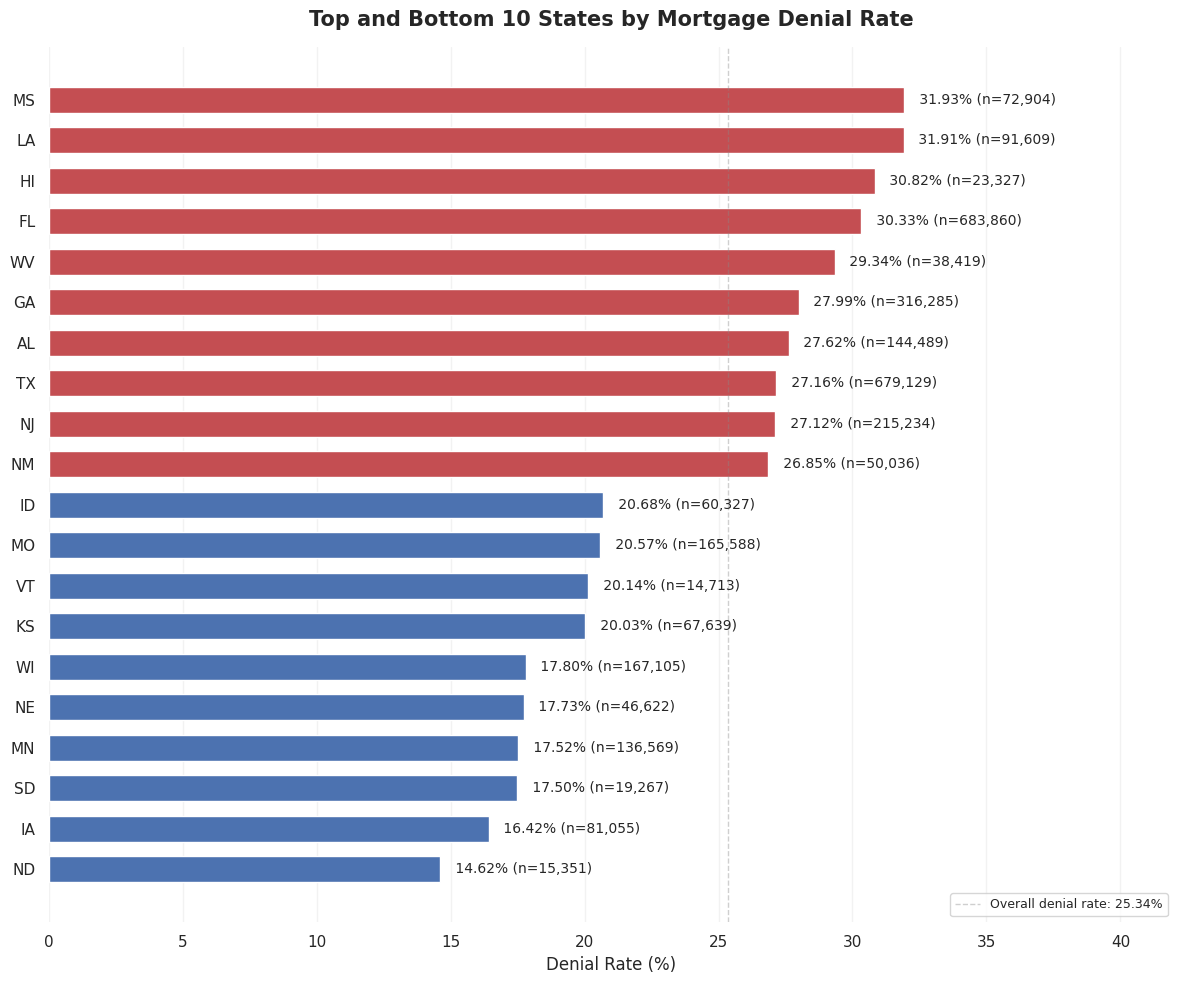

In [12]:
# Top and bottom states by denial rate

# Define state_plot alias to avoid NameError
state_plot = state_results

# Restrict ranking to 50 states and Washington DC
ranking_df = state_plot[
    ~state_plot["state_code"].isin(["PR", "GU", "VI"])
].copy()

top10 = ranking_df.nlargest(10, "denial_rate")
bottom10 = ranking_df.nsmallest(10, "denial_rate")

plot_df = pd.concat(
    [top10, bottom10]
).sort_values("denial_rate", ascending=True)

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

fig, ax = plt.subplots(figsize=(12, 10))

bars = ax.barh(
    plot_df["state_code"].astype(str),
    plot_df["denial_rate"],
    color=colors,
    height=0.65
)

ax.axvline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

for bar, rate, n in zip(
    bars,
    plot_df["denial_rate"],
    plot_df["applications"]
):
    ax.text(
        rate + 0.4,
        bar.get_y() + bar.get_height() / 2,
        f" {rate:.2f}% (n={n:,})",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Top and Bottom 10 States by Mortgage Denial Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Denial Rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 42)

ax.legend(loc="lower right", fontsize=9)

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()

plt.savefig(
    OUT + "denial_rate_top_bottom_states.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

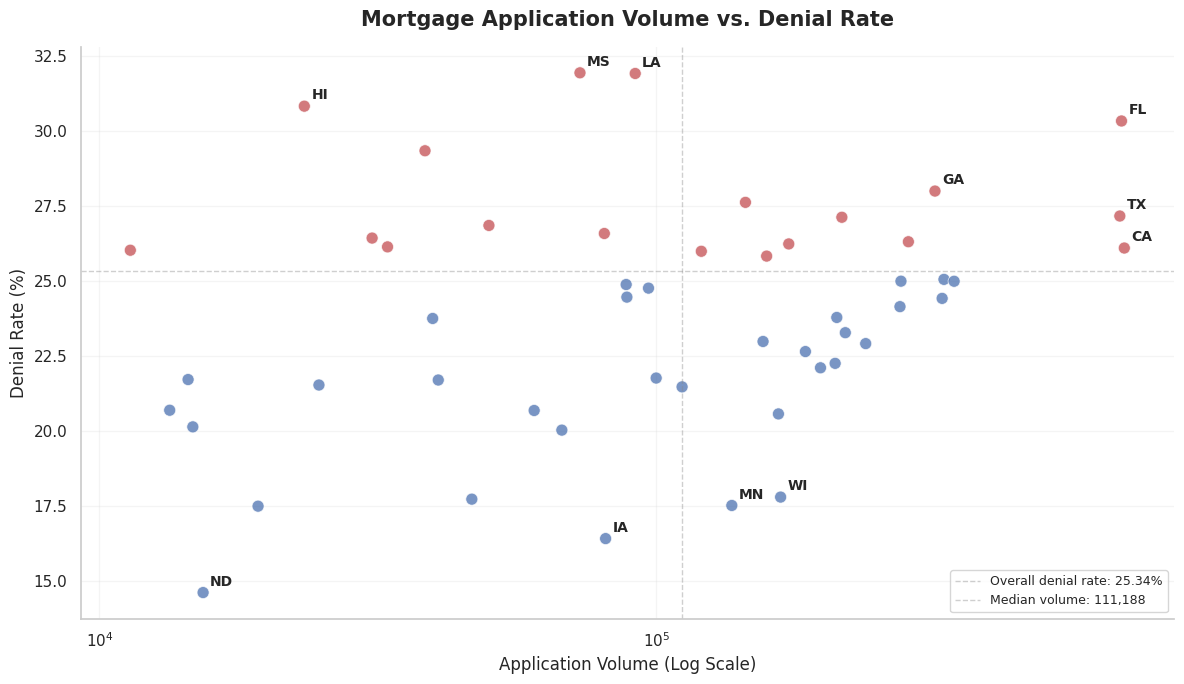

In [13]:
# Application volume versus denial rate

fig, ax = plt.subplots(figsize=(12, 7))

plot_df = ranking_df.copy()

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

ax.scatter(
    plot_df["applications"],
    plot_df["denial_rate"],
    c=colors,
    s=75,
    alpha=0.75,
    edgecolors="white",
    linewidth=0.6
)

# Denial rate baseline
ax.axhline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

# Median application volume
median_volume = plot_df["applications"].median()

ax.axvline(
    median_volume,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Median volume: {median_volume:,.0f}"
)

# Highlight important states
highlight = [
    "FL", "CA", "TX", "MS", "LA",
    "HI", "GA", "ND", "IA", "MN", "WI"
]

for _, row in plot_df.iterrows():

    if row["state_code"] in highlight:

        ax.annotate(
            row["state_code"],
            (
                row["applications"],
                row["denial_rate"]
            ),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=10,
            fontweight="bold"
        )

ax.set_xscale("log")

ax.set_title(
    "Mortgage Application Volume vs. Denial Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Application Volume (Log Scale)")
ax.set_ylabel("Denial Rate (%)")

ax.legend(loc="lower right", fontsize=9)
ax.grid(alpha=0.2)

sns.despine()

plt.tight_layout()

plt.savefig(
    OUT + "state_volume_vs_denial_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

### Insight 3.2 – Geographic Variation in Mortgage Denial Rates

Mortgage denial rates exhibit considerable geographic variation
across the United States.

- **Geographic disparities:** Mississippi (31.93%), Louisiana
  (31.91%), Hawaii (30.82%), and Florida (30.33%) record the
  highest denial rates among U.S. states. In contrast, North
  Dakota (14.62%) and Iowa (16.42%) exhibit substantially
  lower denial rates. The difference between Mississippi and
  North Dakota reaches 17.31 percentage points.

- **Regional patterns:** Several Southern states, including
  Mississippi, Louisiana, Georgia, Alabama, and Florida,
  exhibit above-average denial rates. Conversely, several
  Midwestern states, including North Dakota, Iowa, Minnesota,
  Nebraska, and Wisconsin, exhibit below-average rates.

- **Application volume and denial rates:** Florida stands out
  with both a high denial rate of 30.33% and a substantial
  application volume of 683,860. Its 207,409 denied applications
  account for approximately 9.86% of all denials in S1.

- **Missing geographic information:** The 36,577 applications
  with missing state information exhibit an unusually high
  denial rate of 86.02%, compared with the overall rate of
  25.34%. Although these observations represent only 0.44% of
  S1, their outcome distribution suggests that geographic
  missingness may not be entirely random.

These findings indicate that geographic information may provide
predictive value beyond individual loan characteristics. However,
regional differences may also reflect variations in borrower
profiles, housing markets, loan portfolios, and lender composition.

Geographic associations should therefore not be interpreted as
direct causal effects on mortgage denial.

##RQ3.3 – Lender Analysis

In [14]:
# RQ3.3 - Denial rate by lender

MIN_SAMPLE = 1000

lender_results = denial_summary(S1, "lei")

# Calculate 95% Wilson confidence intervals
lender_results["ci_lower"], lender_results["ci_upper"] = wilson_ci(
    lender_results["denied"],
    lender_results["applications"]
)

# Flag small lenders
lender_results["low_sample"] = (
    lender_results["applications"] < MIN_SAMPLE
)

lender_results = lender_results.sort_values(
    "applications", ascending=False
).reset_index(drop=True)

# Store full results
RQ3_RESULTS["lei"] = lender_results.copy()

# Save full results
lender_results.to_csv(
    OUT + "denial_by_lender.csv",
    index=False
)

print(f"Total lenders: {len(lender_results):,}")
print(f"Overall denial rate: {BASELINE:.2f}%")

display(lender_results.head(10).round(2))

Total lenders: 4,909
Overall denial rate: 25.34%


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
0,549300FGXN1K3HLB1R50,443360,82289,361071,18.56,5.34,-6.78,18.45,18.68,False
1,549300HW662MN1WU8550,423838,57760,366078,13.63,5.11,-11.71,13.52,13.73,False
2,B4TYDEB6GKMZO031MB27,164085,80920,83165,49.32,1.98,23.97,49.07,49.56,False
3,X05BVSK68TQ7YTOSNR22,147224,112530,34694,76.43,1.77,51.09,76.22,76.65,False
4,6BYL5QZYBDK8S7L73M02,128667,54155,74512,42.09,1.55,16.75,41.82,42.36,False
5,5493003GQDUH26DNNH17,125776,43754,82022,34.79,1.52,9.45,34.52,35.05,False
6,549300AG64NHILB7ZP05,112716,33298,79418,29.54,1.36,4.20,29.28,29.81,False
7,549300XQVJ1XBNFA5536,106837,76563,30274,71.66,1.29,46.32,71.39,71.93,False
8,549300VZVN841I2ILS84,105610,3716,101894,3.52,1.27,-21.82,3.41,3.63,False
9,549300DD5QQUHO6PCH70,97323,23564,73759,24.21,1.17,-1.13,23.94,24.48,False


In [15]:
# Lender sample size distribution

print("Application volume distribution:")

display(
    lender_results["applications"]
    .describe(percentiles=[
        0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99
    ])
    .round(2)
)

# Assess coverage at different thresholds
threshold_results = []

for threshold in [100, 500, 1000, 5000, 10000]:

    subset = lender_results[
        lender_results["applications"] >= threshold
    ]

    threshold_results.append({
        "min_applications": threshold,
        "lenders": len(subset),
        "lender_share_pct": (
            len(subset) / len(lender_results) * 100
        ),
        "applications": subset["applications"].sum(),
        "application_coverage_pct": (
            subset["applications"].sum() / len(S1) * 100
        ),
        "denied": subset["denied"].sum(),
        "denied_coverage_pct": (
            subset["denied"].sum()
            / S1["denied_flag"].sum() * 100
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(2))

threshold_df.to_csv(
    OUT + "lender_threshold_assessment.csv",
    index=False
)

Application volume distribution:


,applications
count,4909.00
mean,1690.88
std,11627.59
min,1.00
10%,34.00
25%,67.00
50%,167.00
75%,640.00
90%,2179.60
95%,4904.60


,min_applications,lenders,lender_share_pct,applications,application_coverage_pct,denied,denied_coverage_pct
0,100,3134,63.84,8208031,98.89,2092275,99.47
1,500,1397,28.46,7816426,94.17,2036622,96.82
2,1000,904,18.42,7461625,89.89,1972960,93.80
3,5000,244,4.97,6046558,72.85,1708958,81.25
4,10000,124,2.53,5209399,62.76,1554318,73.89


In [16]:
# Filter lenders with sufficient application volume

lender_plot = lender_results[
    lender_results["applications"] >= MIN_SAMPLE
].copy()

print(f"Eligible lenders: {len(lender_plot):,}")

print("\nDenial rate distribution:")

display(
    lender_plot["denial_rate"]
    .describe()
    .round(2)
)

print("\nTop 10 lenders by application volume:")

display(
    lender_plot.nlargest(10, "applications")
    .round(2)
)

print("\nTop 10 highest denial rates:")

display(
    lender_plot.nlargest(10, "denial_rate")
    .round(2)
)

print("\nTop 10 lowest denial rates:")

display(
    lender_plot.nsmallest(10, "denial_rate")
    .round(2)
)

Eligible lenders: 904

Denial rate distribution:


,denial_rate
count,904.00
mean,19.34
std,15.79
min,0.00
25%,6.65
50%,15.94
75%,27.70
max,100.00



Top 10 lenders by application volume:


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
0,549300FGXN1K3HLB1R50,443360,82289,361071,18.56,5.34,-6.78,18.45,18.68,False
1,549300HW662MN1WU8550,423838,57760,366078,13.63,5.11,-11.71,13.52,13.73,False
2,B4TYDEB6GKMZO031MB27,164085,80920,83165,49.32,1.98,23.97,49.07,49.56,False
3,X05BVSK68TQ7YTOSNR22,147224,112530,34694,76.43,1.77,51.09,76.22,76.65,False
4,6BYL5QZYBDK8S7L73M02,128667,54155,74512,42.09,1.55,16.75,41.82,42.36,False
5,5493003GQDUH26DNNH17,125776,43754,82022,34.79,1.52,9.45,34.52,35.05,False
6,549300AG64NHILB7ZP05,112716,33298,79418,29.54,1.36,4.20,29.28,29.81,False
7,549300XQVJ1XBNFA5536,106837,76563,30274,71.66,1.29,46.32,71.39,71.93,False
8,549300VZVN841I2ILS84,105610,3716,101894,3.52,1.27,-21.82,3.41,3.63,False
9,549300DD5QQUHO6PCH70,97323,23564,73759,24.21,1.17,-1.13,23.94,24.48,False



Top 10 highest denial rates:


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
743,549300S347HTLHLOC775,1332,1332,0,100.00,0.02,74.66,99.71,100.00,False
49,549300Q3ROEQU3D1IW91,24176,21223,2953,87.79,0.29,62.44,87.37,88.19,False
467,984500F03B9034CQB904,2307,1987,320,86.13,0.03,60.79,84.66,87.48,False
174,5493000V86JDJLM0OV13,7111,6100,1011,85.78,0.09,60.44,84.95,86.57,False
259,549300FFVDRROF85IC57,4537,3860,677,85.08,0.05,59.74,84.01,86.09,False
362,5493009XSE00M8B9R434,3107,2594,513,83.49,0.04,58.15,82.14,84.75,False
11,549300YIQ7S7Z8PIHE53,90490,74388,16102,82.21,1.09,56.86,81.96,82.45,False
29,549300CB67L6KPJLHE19,60939,48165,12774,79.04,0.73,53.70,78.71,79.36,False
3,X05BVSK68TQ7YTOSNR22,147224,112530,34694,76.43,1.77,51.09,76.22,76.65,False
287,254900DSZI6CJXJL6Z14,4170,3107,1063,74.51,0.05,49.17,73.16,75.81,False



Top 10 lowest denial rates:


,lei,applications,denied,originated,denial_rate,volume_share,gap_vs_baseline_pp,ci_lower,ci_upper,low_sample
346,549300DCGBXW5FJMV921,3297,0,3297,0.00,0.04,-25.34,0.00,0.12,False
450,549300C8GOC4OYUV0Z32,2428,0,2428,0.00,0.03,-25.34,0.00,0.16,False
538,549300PRAPL43XPYR044,1973,0,1973,0.00,0.02,-25.34,0.00,0.19,False
549,254900DRSIZBQXDCJ875,1937,0,1937,0.00,0.02,-25.34,0.00,0.20,False
698,9845006B80369D0D9F43,1430,0,1430,0.00,0.02,-25.34,0.00,0.27,False
741,549300ANF834QIIFUE57,1335,0,1335,0.00,0.02,-25.34,0.00,0.29,False
750,549300YX5RPSSMR88K92,1306,0,1306,0.00,0.02,-25.34,0.00,0.29,False
493,549300C1ICNCM0V37Y02,2174,1,2173,0.05,0.03,-25.30,0.01,0.26,False
755,5493004M1U54OO4KKE09,1295,2,1293,0.15,0.02,-25.19,0.04,0.56,False
187,5493006L4FQIQFVFNS72,6725,18,6707,0.27,0.08,-25.07,0.17,0.42,False


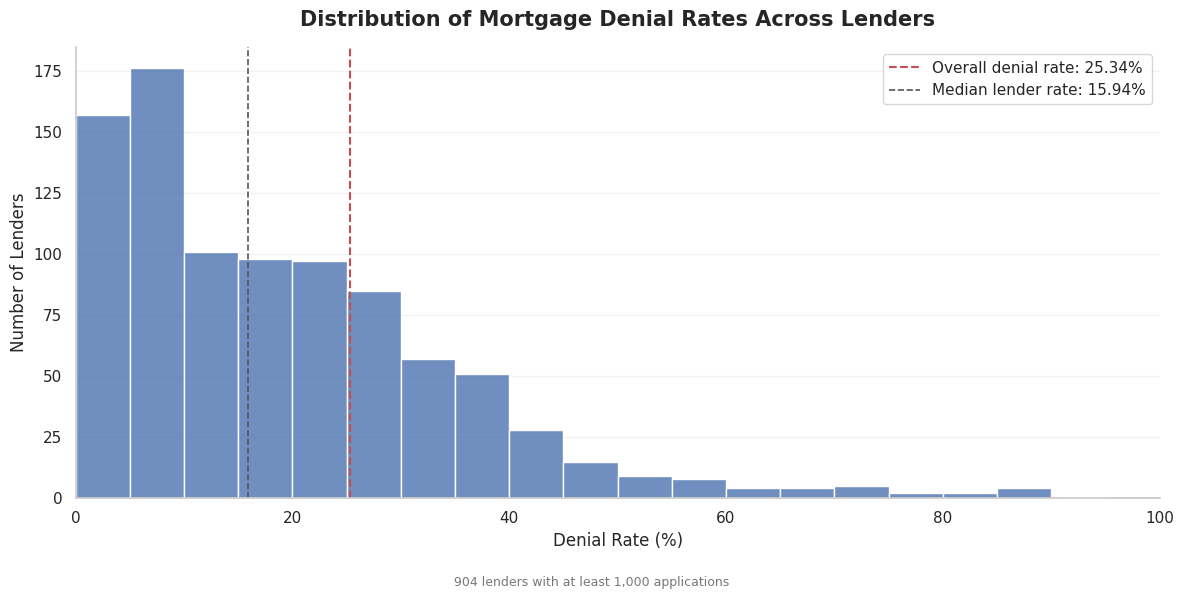

In [17]:
# RQ3.3 - Lender denial rate distribution

fig, ax = plt.subplots(figsize=(12, 6))

sns.histplot(
    data=lender_plot,
    x="denial_rate",
    bins=np.arange(0, 105, 5),
    color="#4C72B0",
    edgecolor="white",
    alpha=0.8,
    ax=ax
)

ax.axvline(
    BASELINE,
    color="#C44E52",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

median_rate = lender_plot["denial_rate"].median()

ax.axvline(
    median_rate,
    color="#555555",
    linestyle="--",
    linewidth=1.2,
    label=f"Median lender rate: {median_rate:.2f}%"
)

ax.set_title(
    "Distribution of Mortgage Denial Rates Across Lenders",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Denial Rate (%)")
ax.set_ylabel("Number of Lenders")
ax.set_xlim(0, 100)

ax.legend()
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine()

fig.text(
    0.5, 0.01,
    f"{len(lender_plot):,} lenders with at least "
    f"{MIN_SAMPLE:,} applications",
    ha="center",
    fontsize=9,
    color="#777777"
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

fig.savefig(
    OUT + "lender_denial_rate_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

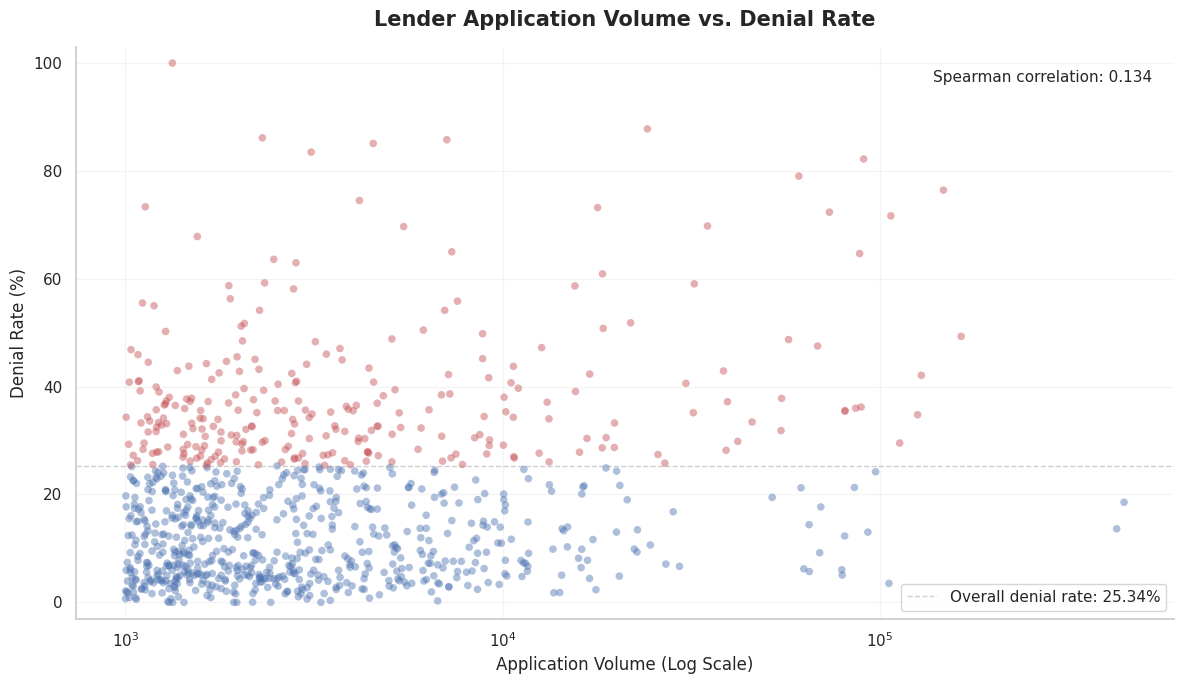

Spearman correlation: 0.1344


In [18]:
# Lender application volume versus denial rate

fig, ax = plt.subplots(figsize=(12, 7))

colors = np.where(
    lender_plot["denial_rate"] > BASELINE,
    "#C44E52",
    "#4C72B0"
)

ax.scatter(
    lender_plot["applications"],
    lender_plot["denial_rate"],
    c=colors,
    alpha=0.45,
    s=30,
    edgecolors="none"
)

ax.axhline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

# Spearman correlation
spearman_corr = lender_plot["applications"].corr(
    lender_plot["denial_rate"],
    method="spearman"
)

ax.text(
    0.98, 0.96,
    f"Spearman correlation: {spearman_corr:.3f}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=11,
    fontweight="medium"
)

ax.set_xscale("log")
ax.set_ylim(-3, 103)

ax.set_title(
    "Lender Application Volume vs. Denial Rate",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Application Volume (Log Scale)")
ax.set_ylabel("Denial Rate (%)")

ax.legend(loc="lower right")
ax.grid(alpha=0.2)

sns.despine()

plt.tight_layout()

fig.savefig(
    OUT + "lender_volume_vs_denial_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Spearman correlation: {spearman_corr:.4f}")

In [19]:
# Create lender size groups

size_df = lender_results.copy()

size_labels = [
    "<100",
    "100–499",
    "500–999",
    "1,000–4,999",
    "5,000–9,999",
    "10,000+"
]

size_df["size_group"] = pd.cut(
    size_df["applications"],
    bins=[0, 100, 500, 1000, 5000, 10000, np.inf],
    labels=size_labels,
    right=False
)

size_summary = (
    size_df.groupby("size_group", observed=True)
    .agg(
        lenders=("lei", "size"),
        applications=("applications", "sum"),
        denied=("denied", "sum"),
        originated=("originated", "sum"),
        mean_lender_rate=("denial_rate", "mean"),
        median_lender_rate=("denial_rate", "median")
    )
    .reset_index()
)

# Application-weighted denial rate
size_summary["denial_rate"] = (
    size_summary["denied"]
    / size_summary["applications"] * 100
)

size_summary["volume_share"] = (
    size_summary["applications"] / len(S1) * 100
)

size_summary["gap_vs_baseline_pp"] = (
    size_summary["denial_rate"] - BASELINE
)

display(size_summary.round(2))

size_summary.to_csv(
    OUT + "denial_by_lender_size.csv",
    index=False
)

,size_group,lenders,applications,denied,originated,mean_lender_rate,median_lender_rate,denial_rate,volume_share,gap_vs_baseline_pp
0,<100,1775,92516,11187,81329,12.15,8.24,12.09,1.11,-13.25
1,100–499,1737,391605,55653,335952,13.85,10.38,14.21,4.72,-11.13
2,500–999,493,354801,63662,291139,17.82,14.99,17.94,4.27,-7.40
3,"1,000–4,999",660,1415067,264002,1151065,18.15,15.46,18.66,17.05,-6.68
4,"5,000–9,999",120,837159,154640,682519,18.33,13.42,18.47,10.09,-6.87
5,"10,000+",124,5209399,1554318,3655081,26.66,22.37,29.84,62.76,4.50


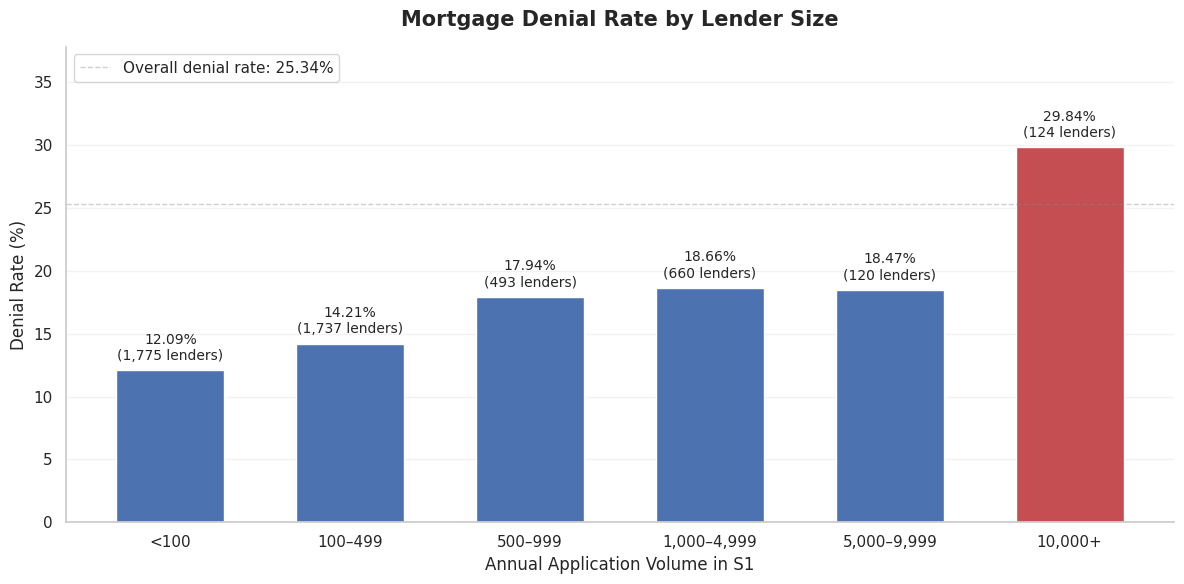

In [20]:
# Denial rate by lender size group

fig, ax = plt.subplots(figsize=(12, 6))

plot_df = size_summary.copy()

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

bars = ax.bar(
    plot_df["size_group"].astype(str),
    plot_df["denial_rate"],
    color=colors,
    width=0.6
)

ax.axhline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

for bar, rate, n in zip(
    bars,
    plot_df["denial_rate"],
    plot_df["lenders"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        rate + 0.6,
        f"{rate:.2f}%\n({n:,} lenders)",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_title(
    "Mortgage Denial Rate by Lender Size",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Annual Application Volume in S1")
ax.set_ylabel("Denial Rate (%)")

ax.set_ylim(
    0,
    max(BASELINE, plot_df["denial_rate"].max()) + 8
)

ax.legend(loc="upper left")
ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine()

plt.tight_layout()

fig.savefig(
    OUT + "denial_by_lender_size.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

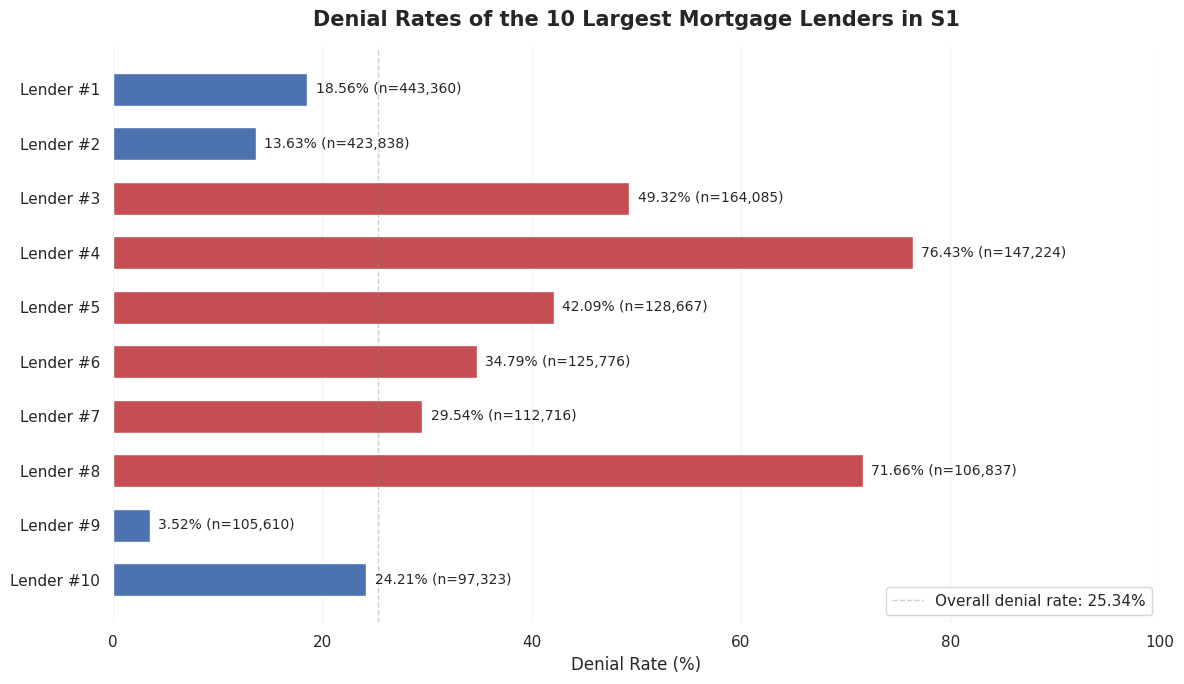

In [21]:
# Top 10 largest lenders

top_lenders = (
    lender_results.nlargest(10, "applications")
    .copy()
    .reset_index(drop=True)
)

top_lenders["rank"] = np.arange(1, 11)

top_lenders["label"] = (
    "Lender #" + top_lenders["rank"].astype(str)
)

top_lenders.to_csv(
    OUT + "top_10_lenders.csv",
    index=False
)

plot_df = top_lenders.sort_values(
    "rank", ascending=False
)

colors = [
    "#C44E52" if rate > BASELINE else "#4C72B0"
    for rate in plot_df["denial_rate"]
]

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    plot_df["label"],
    plot_df["denial_rate"],
    color=colors,
    height=0.6
)

ax.axvline(
    BASELINE,
    color="#888888",
    linestyle="--",
    linewidth=1,
    alpha=0.4,
    label=f"Overall denial rate: {BASELINE:.2f}%"
)

for bar, rate, n in zip(
    bars,
    plot_df["denial_rate"],
    plot_df["applications"]
):

    ax.text(
        rate + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.2f}% (n={n:,})",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Denial Rates of the 10 Largest Mortgage Lenders in S1",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Denial Rate (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)

ax.legend(loc="lower right")

ax.grid(axis="x", alpha=0.25)
ax.grid(axis="y", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()

fig.savefig(
    OUT + "top_10_lenders_denial_rate.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

### Insight 3.3 – Lender-Level Heterogeneity in Mortgage Denial Rates

Mortgage denial rates vary substantially across lending
institutions, revealing considerable institutional heterogeneity.

- **Market concentration:** Of the 4,909 lenders in S1, only
  904 institutions have at least 1,000 applications. Despite
  representing 18.42% of all lenders, these institutions
  account for 89.89% of applications and 93.80% of denials.

- **Denial rate dispersion:** Among eligible lenders, the mean
  denial rate is 19.34%, the median is 15.94%, and the standard
  deviation is 15.79 percentage points. Denial rates range
  from 0% to 100%, demonstrating considerably greater
  heterogeneity than that observed across geographic locations.

- **Lender size:** Institutions with at least 10,000
  applications represent only 2.53% of all lenders but account
  for 62.76% of applications. Their combined denial rate is
  29.84%, compared with 12.09% among lenders with fewer than
  100 applications.

- **Volume-denial relationship:** The Spearman correlation
  between application volume and denial rate is 0.1344 among
  eligible lenders, indicating a weak positive association.
  Lender size alone is therefore insufficient to explain
  differences in denial rates.

- **Variation among large lenders:** Even among institutions
  processing more than 100,000 applications, denial rates
  vary substantially, ranging from 3.52% to 76.43%. This
  suggests that lender-level heterogeneity cannot be
  attributed solely to small application volumes.

The lower unweighted mean lender denial rate (19.34%) relative
to the overall application-weighted rate (25.34%) highlights
the importance of distinguishing institution-level distributions
from application-level outcomes.

These findings motivate the use of lender-grouped validation
in RQ4 to assess whether predictive models generalize to
previously unseen lending institutions.

##RQ3.4 - Lender Portfolio Diagnostics

In [22]:
# RQ3.4 - Define lender groups

high_lenders = lender_plot.nlargest(
    10, "denial_rate"
)["lei"].tolist()

low_lenders = lender_plot.nsmallest(
    10, "denial_rate"
)["lei"].tolist()

high_group = S1[S1["lei"].isin(high_lenders)]
low_group = S1[S1["lei"].isin(low_lenders)]

portfolio_groups = {
    "High-denial lenders": high_group,
    "Low-denial lenders": low_group,
    "All lenders": S1
}

group_summary = []

for name, df in portfolio_groups.items():

    group_summary.append({
        "group": name,
        "lenders": df["lei"].nunique(),
        "applications": len(df),
        "denied": df["denied_flag"].sum(),
        "denial_rate": df["denied_flag"].mean() * 100
    })

portfolio_group_summary = pd.DataFrame(group_summary)

display(portfolio_group_summary.round(2))

portfolio_group_summary.to_csv(
    OUT + "lender_portfolio_group_summary.csv",
    index=False
)

,group,lenders,applications,denied,denial_rate
0,High-denial lenders,10,345393,275286,79.70
1,Low-denial lenders,10,23900,21,0.09
2,All lenders,4909,8300547,2103462,25.34


In [23]:
# Compare portfolio composition across lender groups

PORTFOLIO_COLS = [
    "loan_type",
    "loan_purpose",
    "lien_status",
    "construction_method"
]

portfolio_results = {}

for col in PORTFOLIO_COLS:

    results = []

    for name, df in portfolio_groups.items():

        summary = (
            df.groupby(col, observed=True, dropna=False)
            .agg(
                applications=("denied_flag", "size"),
                denied=("denied_flag", "sum")
            )
            .reset_index()
        )

        summary["portfolio_share"] = (
            summary["applications"] / len(df) * 100
        )

        summary["denial_rate"] = (
            summary["denied"] /
            summary["applications"] * 100
        )

        summary["group"] = name

        summary["label"] = (
            summary[col].astype(str)
            .map(LABELS[col])
            .fillna(summary[col].astype(str))
        )

        results.append(summary)

    result = pd.concat(results, ignore_index=True)

    portfolio_results[col] = result

    result.to_csv(
        OUT + f"lender_portfolio_{col}.csv",
        index=False
    )

    print(f"\n--- Portfolio composition: {col} ---")

    comparison = result.pivot(
        index="label",
        columns="group",
        values="portfolio_share"
    ).reindex(columns=list(portfolio_groups)).fillna(0)

    display(comparison.round(2))

    print(f"\n--- Denial rate: {col} ---")

    comparison_rate = result.pivot(
        index="label",
        columns="group",
        values="denial_rate"
    ).reindex(columns=list(portfolio_groups))

    display(comparison_rate.round(2))


--- Portfolio composition: loan_type ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Conventional,91.16,89.82,79.53
FHA,7.25,7.78,12.92
FSA/RHS,0.00,0.11,0.50
VA,1.58,2.28,7.05



--- Denial rate: loan_type ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Conventional,79.09,0.07,26.71
FHA,86.38,0.32,22.42
FSA/RHS,100.00,0.00,12.71
VA,84.61,0.18,16.10



--- Portfolio composition: loan_purpose ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Cash-out refinancing,24.32,11.86,14.05
Home improvement,10.44,0.03,11.72
Home purchase,33.37,71.22,50.09
Not applicable,0.00,0.00,0.04
Other purpose,23.32,8.12,12.99
Refinancing,8.55,8.77,11.11


... (6 outputs left out)


--- Portfolio composition: construction_method ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Manufactured home,29.79,0.37,5.47
Site-built,70.21,99.63,94.53



--- Denial rate: construction_method ---


group,High-denial lenders,Low-denial lenders,All lenders
label,,,
Manufactured home,82.67,0.00,59.99
Site-built,78.44,0.09,23.34


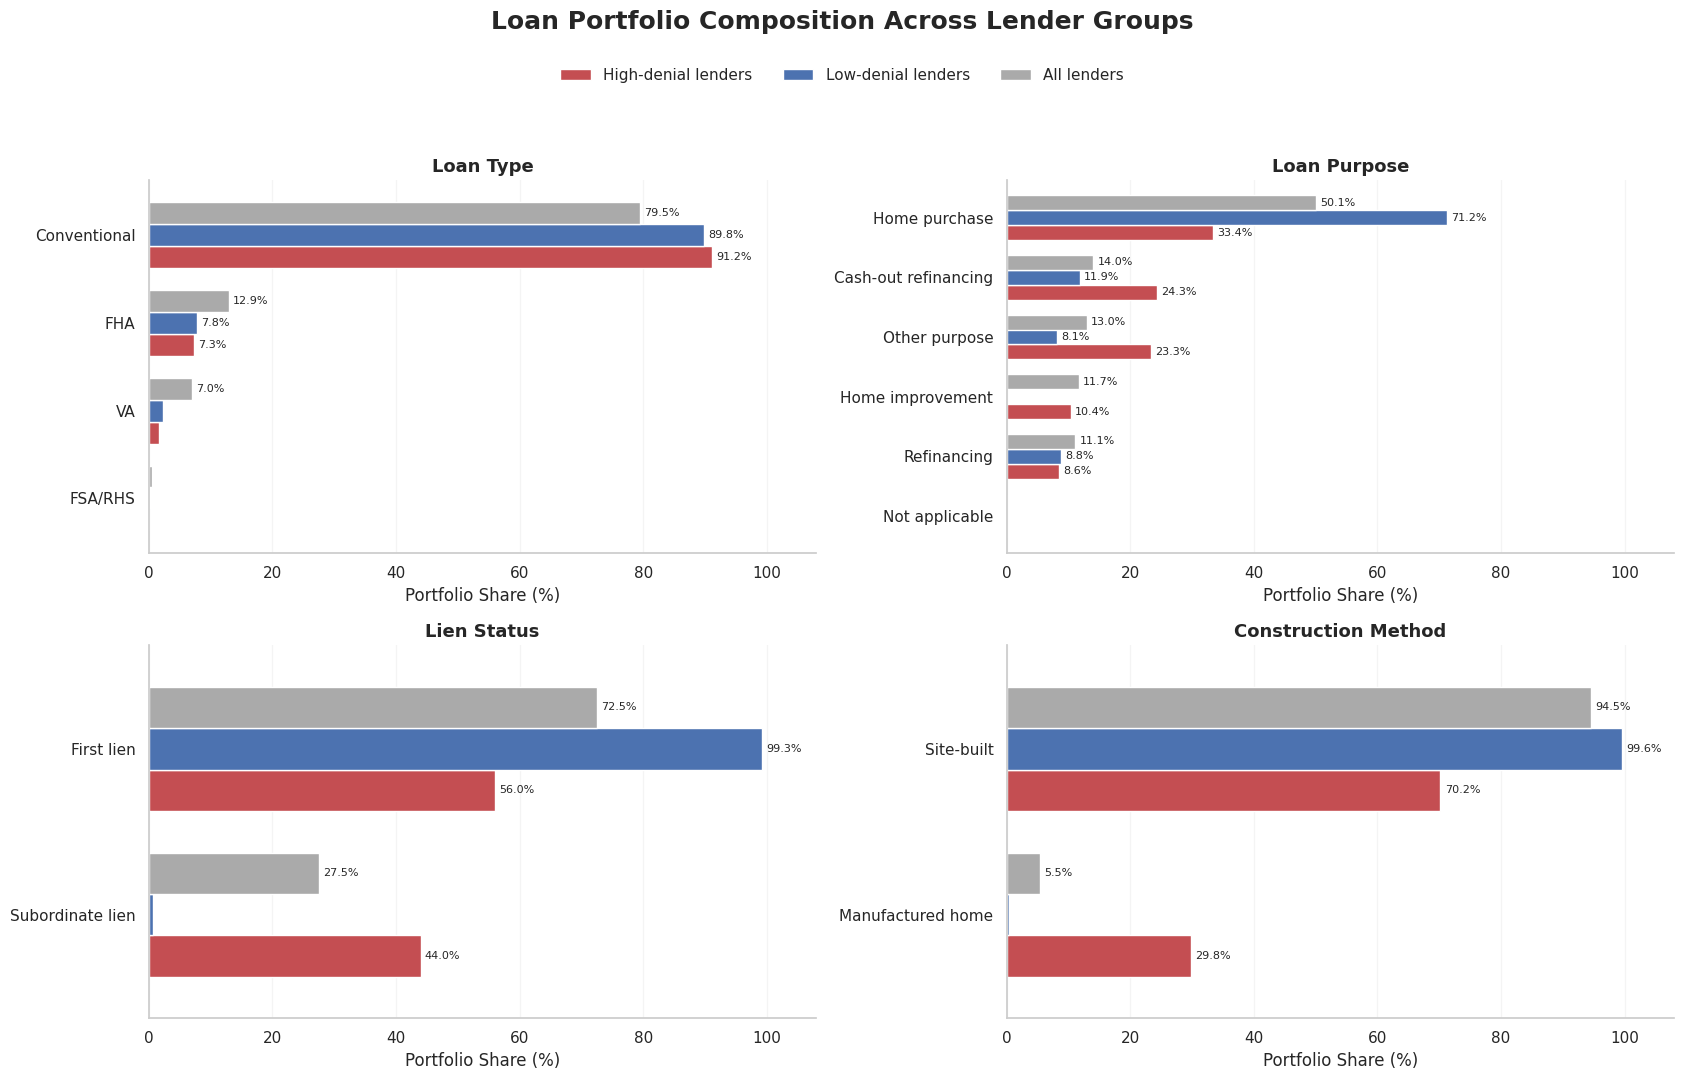

In [24]:
# RQ3.4 - Portfolio composition comparison

GROUP_ORDER = [
    "High-denial lenders",
    "Low-denial lenders",
    "All lenders"
]

GROUP_COLORS = [
    "#C44E52",
    "#4C72B0",
    "#AAAAAA"
]

PORTFOLIO_TITLES = {
    "loan_type": "Loan Type",
    "loan_purpose": "Loan Purpose",
    "lien_status": "Lien Status",
    "construction_method": "Construction Method"
}

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

for ax, (col, title) in zip(
    axes.flatten(),
    PORTFOLIO_TITLES.items()
):

    df = portfolio_results[col].copy()

    pivot = df.pivot(
        index="label",
        columns="group",
        values="portfolio_share"
    ).reindex(columns=GROUP_ORDER).fillna(0)

    pivot = pivot.sort_values(
        "All lenders", ascending=True
    )

    pivot.plot(
        kind="barh",
        ax=ax,
        color=GROUP_COLORS,
        width=0.75,
        legend=False
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Portfolio Share (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 108)

    for container in ax.containers:

        labels = [
            f"{bar.get_width():.1f}%"
            if bar.get_width() >= 3 else ""
            for bar in container
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8
        )

    ax.grid(axis="x", alpha=0.2)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Loan Portfolio Composition Across Lender Groups",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.90])

fig.savefig(
    OUT + "lender_portfolio_composition.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

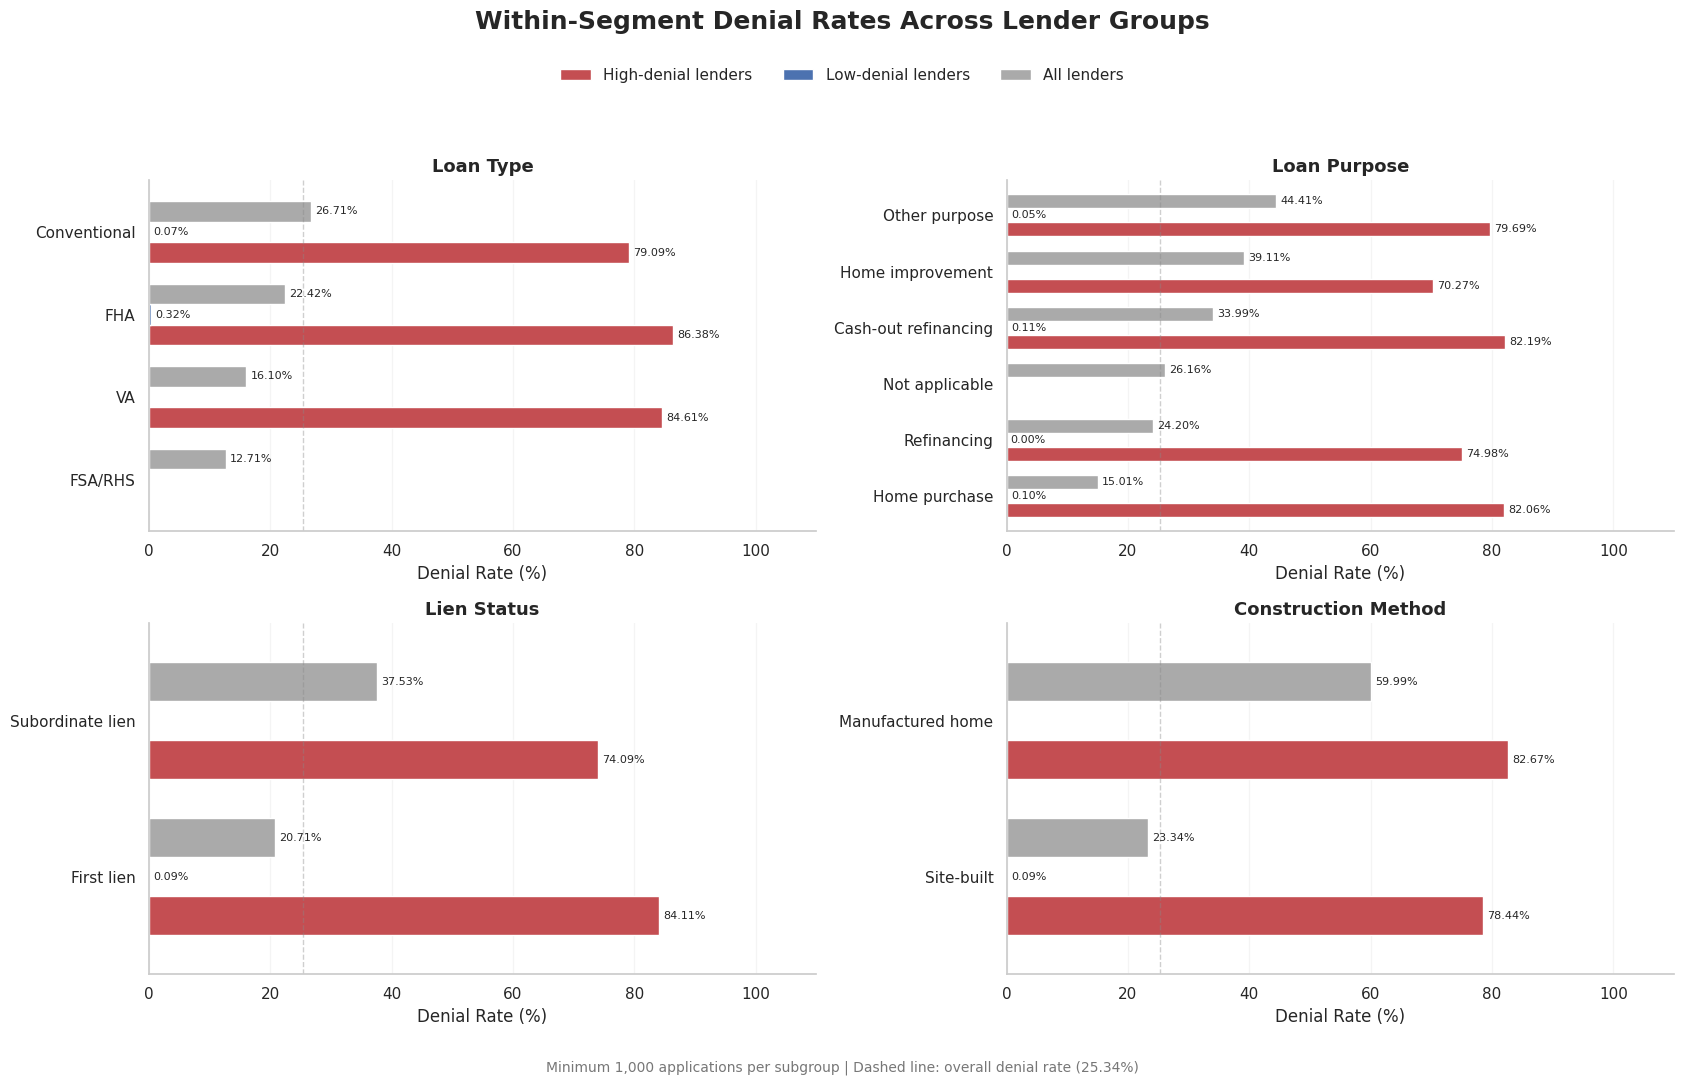

In [25]:
# RQ3.4 - Within-segment denial rate comparison

MIN_SEGMENT_SAMPLE = 1000

fig, axes = plt.subplots(2, 2, figsize=(17, 11))

for ax, (col, title) in zip(
    axes.flatten(),
    PORTFOLIO_TITLES.items()
):

    df = portfolio_results[col].copy()

    # Mask insufficient sample sizes
    df["plot_rate"] = df["denial_rate"].where(
        df["applications"] >= MIN_SEGMENT_SAMPLE
    )

    pivot = df.pivot(
        index="label",
        columns="group",
        values="plot_rate"
    ).reindex(columns=GROUP_ORDER)

    pivot = pivot.dropna(how="all")

    pivot = pivot.sort_values(
        "All lenders", ascending=True
    )

    pivot.plot(
        kind="barh",
        ax=ax,
        color=GROUP_COLORS,
        width=0.75,
        legend=False
    )

    # Overall baseline
    ax.axvline(
        BASELINE,
        color="#888888",
        linestyle="--",
        linewidth=1,
        alpha=0.4
    )

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Denial Rate (%)")
    ax.set_ylabel("")
    ax.set_xlim(0, 110)

    for container, group in zip(
        ax.containers, GROUP_ORDER
    ):

        labels = [
            f"{v:.2f}%" if pd.notna(v) else ""
            for v in pivot[group]
        ]

        ax.bar_label(
            container,
            labels=labels,
            padding=3,
            fontsize=8
        )

    ax.grid(axis="x", alpha=0.2)
    ax.grid(axis="y", visible=False)

    sns.despine(ax=ax)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=3,
    frameon=False
)

fig.suptitle(
    "Within-Segment Denial Rates Across Lender Groups",
    fontsize=18,
    fontweight="bold",
    y=0.98
)

fig.text(
    0.5,
    0.015,
    f"Minimum {MIN_SEGMENT_SAMPLE:,} applications per subgroup | "
    f"Dashed line: overall denial rate ({BASELINE:.2f}%)",
    ha="center",
    fontsize=10,
    color="#777777"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.90])

fig.savefig(
    OUT + "lender_portfolio_denial_rates.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

### Insight 3.4 – Loan Portfolio Composition and Lender Heterogeneity

The comparison between the 10 highest-denial and 10 lowest-denial
eligible lenders reveals substantial differences in both portfolio
composition and observed mortgage outcomes.

- **Portfolio specialization:** High-denial lenders exhibit a
  significantly different product mix, with manufactured homes
  accounting for 29.79% of their applications, compared with
  5.47% across all lenders. Subordinate-lien loans also account
  for 43.99%, compared with the overall share of 27.51%.

- **Loan purpose composition:** High-denial lenders have greater
  exposure to cash-out refinancing (24.32%) and other-purpose
  loans (23.32%). In contrast, low-denial lenders concentrate
  primarily on home purchase applications (71.22%), first-lien
  loans (99.25%), and site-built properties (99.63%).

- **Within-segment differences:** Portfolio composition alone
  does not fully account for the observed denial rate gap.
  Among conventional loans, high-denial lenders exhibit a
  denial rate of 79.09%, compared with 0.07% among low-denial
  lenders. Similar differences persist within home purchase,
  first-lien, and site-built property segments.

- **Potential aggregation effects:** Across all lenders,
  subordinate-lien loans have a higher denial rate than
  first-lien loans (37.53% versus 20.71%). However, this
  relationship reverses among high-denial lenders (74.09%
  versus 84.11%), suggesting that aggregate relationships
  may be influenced by lender composition and interactions
  between loan characteristics.

Overall, observable loan portfolio characteristics provide a
partial explanation for lender-level heterogeneity. Additional
differences may be associated with borrower risk profiles,
underwriting practices, business models, and reporting processes.

However, the extreme lender groups are selected using their
observed denial rates. Consequently, this analysis is exploratory
and does not establish independent institutional effects or
causal relationships.